<a href="https://colab.research.google.com/github/SelinBeyaz01/BUS392-Steam-Project/blob/Anjani-Analysis/BUS392_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install kagglehub

In [7]:
import kagglehub
path = kagglehub.dataset_download("hubertsidorowicz/steam-games-dataset-daily-updates")

Using Colab cache for faster access to the 'steam-games-dataset-daily-updates' dataset.


In [8]:
import pandas as pd
gamesData_location = path + "/steam_games.csv"
gamesData = pd.read_csv(gamesData_location)
gamesData.head()

/tmp/ipykernel_1685/1104197516.py:3: DtypeWarning: Columns (30,31,32) have mixed types. Specify dtype option on import or set low_memory=False.
  gamesData = pd.read_csv(gamesData_location)


,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,genres,categories,...,linux,header_image,screenshots,movies,website,support_url,support_email,metacritic_url,steam_store_available,steam_spy_available
0,2582880,Northrealm Tribes,2026-10-20,0.00,free,"0 .. 20,000","[""DevSanja""]","[""DevSanja""]","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,True,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257460676, ""name"": ""Northrealm Tribes:...",NaN,NaN,ma.schleufe@gmx.de,NaN,True,True
1,3508520,Echoes of the Abyss,2026-10-21,0.99,paid,"0 .. 20,000","[""lijj1235666""]","[""lij1235666""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257108877, ""name"": ""Bounce ball simula...",NaN,NaN,q1w2e3_r42023@qq.com,NaN,True,True
2,1508190,Finding Words,2026-10-21,3.99,paid,"0 .. 20,000","[""Odd Build""]","[""Odd Build""]","[{""id"": ""4"", ""description"": ""Casual""}]","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257459902, ""name"": ""Finding Words Trai...",NaN,criandomeujogo.com,criandomeujogo@hotmail.com,NaN,True,True
3,3639110,Terror In The Shadowrealms,2026-10-21,1.99,paid,"0 .. 20,000","[""Onigumo69""]","[""Onigumo69""]","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257421609, ""name"": ""Terror In The Shad...",NaN,NaN,onigumo69@outlook.com,NaN,True,True
4,1564060,Lighthouse of Madness,2026-10-21,13.99,paid,"0 .. 20,000","[""Flying Jack Studios""]","[""Flying Jack Productions""]","[{""id"": ""25"", ""description"": ""Adventure""}, {""i...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 256900399, ""name"": ""Lighthouse of Madn...",https://lighthouseofmadness.com,https://www.flyingjack.com.br,productions@flyingjack.com.br,NaN,True,True


In [11]:
import pandas as pd
import numpy as np

analysis = gamesData[['app_id', 'name', 'release_date', 'estimated_owners', 'positive', 'negative']].copy()
analysis['release_date'] = pd.to_datetime(analysis['release_date'], errors='coerce')
analysis['positive'] = pd.to_numeric(analysis['positive'], errors='coerce').fillna(0)
analysis['negative'] = pd.to_numeric(analysis['negative'], errors='coerce').fillna(0)
analysis['total_reviews'] = analysis['positive'] + analysis['negative']
analysis = analysis.dropna(subset=['app_id', 'name', 'release_date'])
analysis = analysis.drop_duplicates(subset='app_id')

def owner_midpoint_fixed(owner_range):
    try:
        clean_range = str(owner_range).replace(',', '').replace(' - ', ' .. ')
        low, high = clean_range.split(' .. ')
        return (int(low) + int(high)) / 2
    except:
        return np.nan

analysis['estimated_owners_num'] = analysis['estimated_owners'].apply(owner_midpoint_fixed)

reference_date = analysis['release_date'].max()
analysis['age_days'] = (reference_date - analysis['release_date']).dt.days
analysis['age_years'] = analysis['age_days'] / 365.25
analysis['age_months'] = analysis['age_days'] / 30.44

age_data = analysis[(analysis['age_months'] >= 6) & (analysis['total_reviews'] > 0)].copy()

age_data['positive_per_year'] = age_data['positive'] / age_data['age_years']
age_data['negative_per_year'] = age_data['negative'] / age_data['age_years']
age_data['positive_per_month'] = age_data['positive'] / age_data['age_months']
age_data['negative_per_month'] = age_data['negative'] / age_data['age_months']

def age_group(years):
    if years < 2:
        return '1) Under 2 years'
    elif years < 5:
        return '2) 2-5 years'
    elif years < 10:
        return '3) 5-10 years'
    else:
        return '4) 10+ years'

age_data['age_group'] = age_data['age_years'].apply(age_group)

print("Reference date:", reference_date.date())
print("Games used in the age analysis:", len(age_data))
age_data['age_group'].value_counts().sort_index()

Reference date: 2026-11-22
Games used in the age analysis: 83028


,count
age_group,
1) Under 2 years,7455
2) 2-5 years,30128
3) 5-10 years,35911
4) 10+ years,9534


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

age_data['positive_rate'] = age_data['positive'] / age_data['total_reviews']

age_summary = age_data.groupby('age_group').agg(
    games_count=('app_id', 'count'),
    avg_positive=('positive', 'mean'),
    avg_negative=('negative', 'mean'),
    median_positive=('positive', 'median'),
    median_negative=('negative', 'median'),
    avg_positive_rate=('positive_rate', 'mean'),
    avg_positive_per_year=('positive_per_year', 'mean'),
    avg_negative_per_year=('negative_per_year', 'mean'),
    avg_positive_per_month=('positive_per_month', 'mean'),
    avg_negative_per_month=('negative_per_month', 'mean')
).round(2)

age_summary

,games_count,avg_positive,avg_negative,median_positive,median_negative,avg_positive_rate,avg_positive_per_year,avg_negative_per_year,avg_positive_per_month,avg_negative_per_month
age_group,,,,,,,,,,
1) Under 2 years,7455,495.63,87.68,10.0,1.0,0.84,335.10,57.32,27.93,4.78
2) 2-5 years,30128,728.44,134.38,11.0,2.0,0.79,229.59,41.31,19.13,3.44
3) 5-10 years,35911,1327.36,237.32,18.0,6.0,0.73,184.49,32.82,15.38,2.74
4) 10+ years,9534,5712.93,782.53,140.0,52.0,0.71,438.71,62.02,36.56,5.17


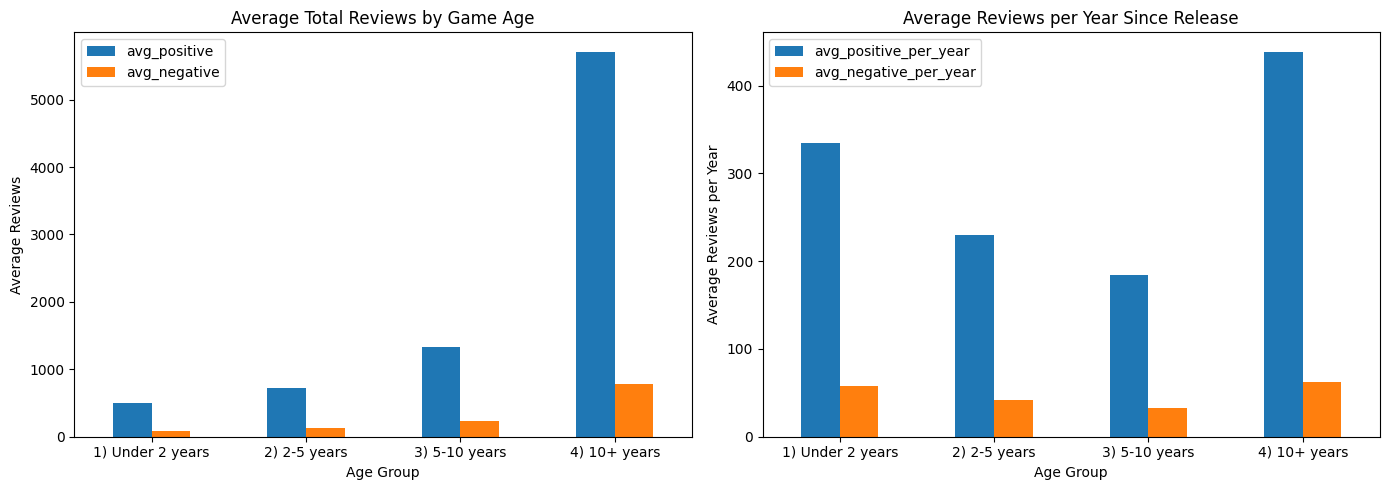

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

age_summary[['avg_positive', 'avg_negative']].plot(kind='bar', ax=axes[0])
axes[0].set_title('Average Total Reviews by Game Age')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Average Reviews')
axes[0].tick_params(axis='x', rotation=0)

age_summary[['avg_positive_per_year', 'avg_negative_per_year']].plot(kind='bar', ax=axes[1])
axes[1].set_title('Average Reviews per Year Since Release')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Average Reviews per Year')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

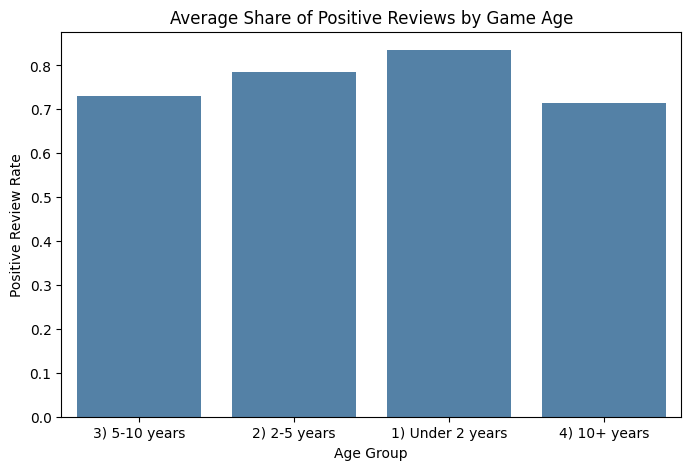

Spearman correlation of each metric with game age:


,age_years
positive,0.272
negative,0.398
positive_rate,-0.255
positive_per_year,0.018
negative_per_year,0.202


In [14]:
plt.figure(figsize=(8, 5))
sns.barplot(data=age_data, x='age_group', y='positive_rate', estimator='mean', errorbar=None, color='steelblue')
plt.title('Average Share of Positive Reviews by Game Age')
plt.xlabel('Age Group')
plt.ylabel('Positive Review Rate')
plt.show()

age_correlations = age_data[[
    'age_years', 'positive', 'negative', 'positive_rate',
    'positive_per_year', 'negative_per_year'
]].corr(method='spearman')['age_years'].drop('age_years').round(3)

print("Spearman correlation of each metric with game age:")
age_correlations

Games used: 83094
Share of games with playtime above 0: 0.088


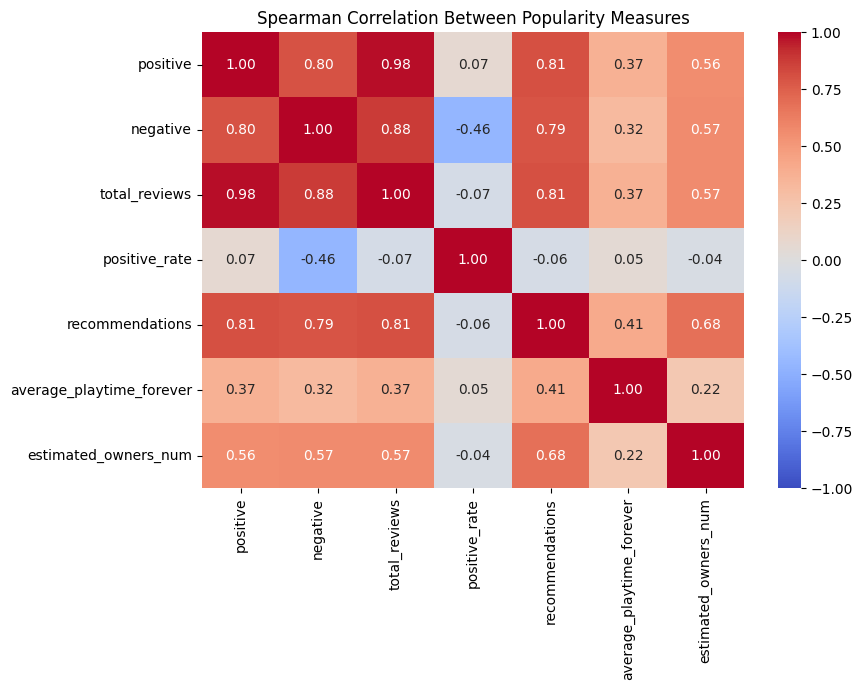

In [15]:
corr_data = gamesData[['app_id', 'positive', 'negative', 'recommendations',
                       'average_playtime_forever', 'estimated_owners']].copy()

for column in ['positive', 'negative', 'recommendations', 'average_playtime_forever']:
    corr_data[column] = pd.to_numeric(corr_data[column], errors='coerce')

corr_data = corr_data.drop_duplicates(subset='app_id')
corr_data['estimated_owners_num'] = corr_data['estimated_owners'].apply(owner_midpoint_fixed)
corr_data['total_reviews'] = corr_data['positive'].fillna(0) + corr_data['negative'].fillna(0)
corr_data = corr_data[corr_data['total_reviews'] > 0].copy()
corr_data['positive_rate'] = corr_data['positive'] / corr_data['total_reviews']

corr_columns = ['positive', 'negative', 'total_reviews', 'positive_rate',
                'recommendations', 'average_playtime_forever', 'estimated_owners_num']

spearman_corr = corr_data[corr_columns].corr(method='spearman').round(2)

print("Games used:", len(corr_data))
print("Share of games with playtime above 0:", round((corr_data['average_playtime_forever'] > 0).mean(), 3))

plt.figure(figsize=(9, 7))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Spearman Correlation Between Popularity Measures')
plt.tight_layout()
plt.show()

In [16]:
def rating_level(rate):
    if rate >= 0.8:
        return '1) High (80%+)'
    elif rate >= 0.5:
        return '2) Mixed (50-79%)'
    else:
        return '3) Low (under 50%)'

rated_games = corr_data[corr_data['total_reviews'] >= 50].copy()
rated_games['rating_level'] = rated_games['positive_rate'].apply(rating_level)

rating_summary = rated_games.groupby('rating_level').agg(
    games_count=('app_id', 'count'),
    avg_recommendations=('recommendations', 'mean'),
    median_recommendations=('recommendations', 'median'),
    avg_playtime=('average_playtime_forever', 'mean'),
    avg_owners=('estimated_owners_num', 'mean'),
    median_owners=('estimated_owners_num', 'median')
).round(2)

rating_summary

,games_count,avg_recommendations,median_recommendations,avg_playtime,avg_owners,median_owners
rating_level,,,,,,
1) High (80%+),16898,6813.66,348.0,286.81,376350.46,35000.0
2) Mixed (50-79%),11986,2377.70,231.0,157.40,242195.90,35000.0
3) Low (under 50%),1814,1391.74,182.0,184.93,118792.72,35000.0


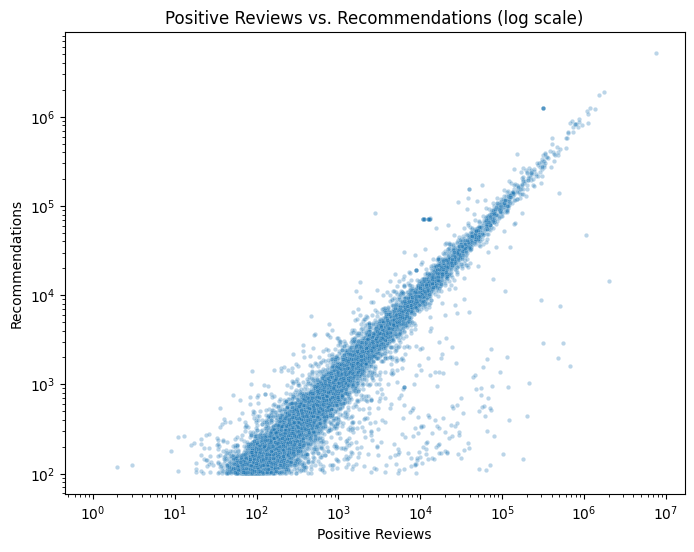

In [17]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=corr_data, x='positive', y='recommendations', alpha=0.3, s=10)
plt.xscale('log')
plt.yscale('log')
plt.title('Positive Reviews vs. Recommendations (log scale)')
plt.xlabel('Positive Reviews')
plt.ylabel('Recommendations')
plt.show()